# Phase C2B — Advanced Graphical EDA (Corrected)

This notebook is the advanced graphical/deep-dive layer after C2.

It uses the normalized observable Dataset V1 and focuses on:
- advanced behavioural patterns
- segment differences
- interaction effects
- nonlinear relationships
- intervention/action support
- observed outcome heterogeneity
- anomaly review
- statistically supported exploratory insights

C2 remains the broad statistical/relational EDA.

Important:
- No model training
- No train/test split
- No final feature freezing
- No latent sidecar
- No hardcoded numerical findings
- No causal claims from observed action success


In [16]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

CURRENT = Path.cwd()

if (CURRENT / "data" / "normalized").exists():
    PROJECT_ROOT = CURRENT
elif (CURRENT.parent / "data" / "normalized").exists():
    PROJECT_ROOT = CURRENT.parent
else:
    raise FileNotFoundError(
        "Could not locate project root containing data/normalized."
    )

NORM_DIR = PROJECT_ROOT / "data" / "normalized"
CONTRACT_DIR = PROJECT_ROOT / "reports" / "ml_contract"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda_graphical"
DOCS_DIR = PROJECT_ROOT / "docs"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR.mkdir(parents=True, exist_ok=True)

TABLES = [
    "customers.csv",
    "subscriptions.csv",
    "payment_attempts.csv",
    "recovery_cases.csv",
    "recovery_events.csv",
    "action_log.csv",
    "case_outcomes.csv",
    "ml_datamart.csv",
]

dfs = {}
for filename in TABLES:
    path = NORM_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing normalized table: {path}")
    dfs[path.stem] = pd.read_csv(path, low_memory=False)

df_ml = dfs["ml_datamart"]

if "y" in df_ml.columns:
    target_col = "y"
elif "y_intervention" in df_ml.columns:
    target_col = "y_intervention"
else:
    raise ValueError("ml_datamart must contain `y` or `y_intervention`.")

df_ml[target_col] = pd.to_numeric(df_ml[target_col], errors="coerce")

candidate_path = CONTRACT_DIR / "candidate_features.csv"
df_candidates = (
    pd.read_csv(candidate_path)
    if candidate_path.exists()
    else pd.DataFrame(columns=["feature_group", "column"])
)

candidate_cols = [
    c for c in df_candidates["column"].dropna().unique()
    if c in df_ml.columns
]

print(f"Loaded {len(dfs)} normalized tables.")
print(f"Target: {target_col}")
print(f"Candidate columns available: {len(candidate_cols)}")


Loaded 8 normalized tables.
Target: y
Candidate columns available: 32


## Insight Tracking Engine

In [17]:

insights_log = []

def record_insight(
    section,
    finding,
    evidence,
    statistical_support,
    interpretation,
    ml_implication,
    caveat="Exploratory association; not a causal treatment estimate.",
):
    row = {
        "section": section,
        "finding": finding,
        "evidence": evidence,
        "statistical_support": statistical_support,
        "interpretation": interpretation,
        "ml_implication": ml_implication,
        "caveat": caveat,
    }
    insights_log.append(row)

    print("\n" + "=" * 70)
    print("EDA INSIGHT")
    print("=" * 70)
    for k, v in row.items():
        print(f"{k}: {v}")

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(REPORT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

def rate_table(df, group_cols, min_count=30):
    result = (
        df.groupby(group_cols, dropna=False)[target_col]
        .agg(
            observations="size",
            observed_success_rate="mean"
        )
        .reset_index()
    )
    return result[result["observations"] >= min_count].copy()

def qbin_table(df, col, q=5):
    temp = df[[col, target_col]].dropna().copy()
    if temp.empty or temp[col].nunique() < q + 2:
        return None
    try:
        temp["bin"] = pd.qcut(temp[col], q=q, duplicates="drop")
    except ValueError:
        return None
    return (
        temp.groupby("bin", observed=False)[target_col]
        .agg(
            observations="size",
            observed_success_rate="mean"
        )
        .reset_index()
    )


## 1. Customer × Subscription Advanced Behaviour

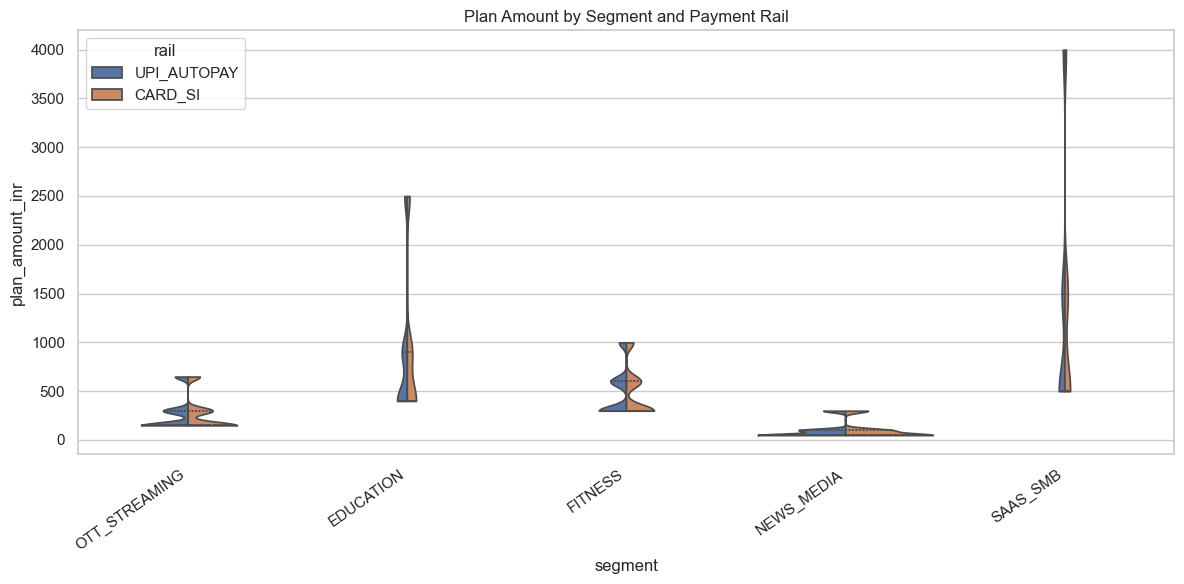


EDA INSIGHT
section: Customer / Subscription Behaviour
finding: Plan amounts differ across customer segments.
evidence: Segment medians: {'NEWS_MEDIA': 49.0, 'OTT_STREAMING': 149.0, 'FITNESS': 299.0, 'EDUCATION': 399.0, 'SAAS_SMB': 499.0}
statistical_support: Kruskal-Wallis H=14799.693, p=0.0000e+00
interpretation: Commercial exposure is heterogeneous across segments.
ml_implication: Retain segment and amount-related variables as separate candidate features; do not substitute one for the other automatically.
caveat: Exploratory association; not a causal treatment estimate.


In [18]:

if {"customer_id"}.issubset(dfs["customers"].columns) and \
   {"customer_id"}.issubset(dfs["subscriptions"].columns):

    customer_sub = dfs["subscriptions"].merge(
        dfs["customers"],
        on="customer_id",
        how="left",
        validate="many_to_one",
    )

    if {"segment", "rail", "plan_amount_inr"}.issubset(customer_sub.columns):
        plt.figure(figsize=(12, 6))
        rail_levels = customer_sub["rail"].dropna().nunique()

        if rail_levels == 2:
            sns.violinplot(
                data=customer_sub,
                x="segment",
                y="plan_amount_inr",
                hue="rail",
                split=True,
                inner="quart",
                cut=0,
            )
        else:
            sns.violinplot(
                data=customer_sub,
                x="segment",
                y="plan_amount_inr",
                hue="rail",
                inner="quart",
                cut=0,
            )

        plt.title("Plan Amount by Segment and Payment Rail")
        plt.xticks(rotation=35, ha="right")
        save_plot("customer_subscription_amount_segment_rail.png")

        groups = [
            g["plan_amount_inr"].dropna()
            for _, g in customer_sub.groupby("segment")
        ]
        groups = [g for g in groups if len(g) > 0]

        if len(groups) >= 2:
            h_stat, p = stats.kruskal(*groups)
            medians = (
                customer_sub.groupby("segment")["plan_amount_inr"]
                .median()
                .sort_values()
            )

            record_insight(
                section="Customer / Subscription Behaviour",
                finding="Plan amounts differ across customer segments.",
                evidence=f"Segment medians: {medians.to_dict()}",
                statistical_support=f"Kruskal-Wallis H={h_stat:.3f}, p={p:.4e}",
                interpretation=(
                    "Commercial exposure is heterogeneous across segments."
                ),
                ml_implication=(
                    "Retain segment and amount-related variables as separate "
                    "candidate features; do not substitute one for the other automatically."
                ),
            )


## 2. Failure Mechanisms and Economic Exposure

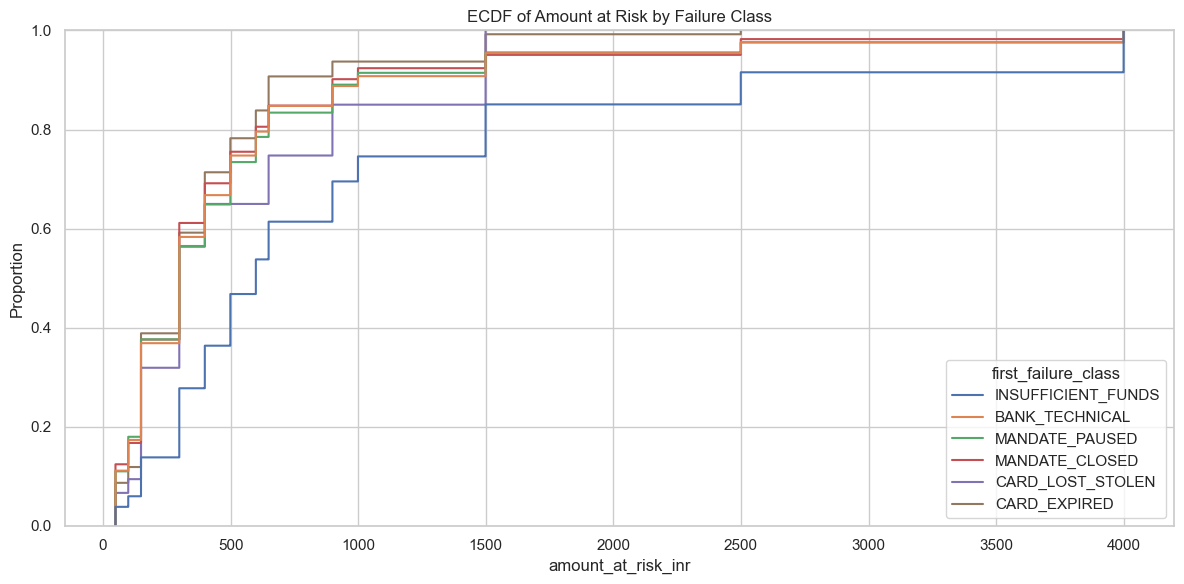

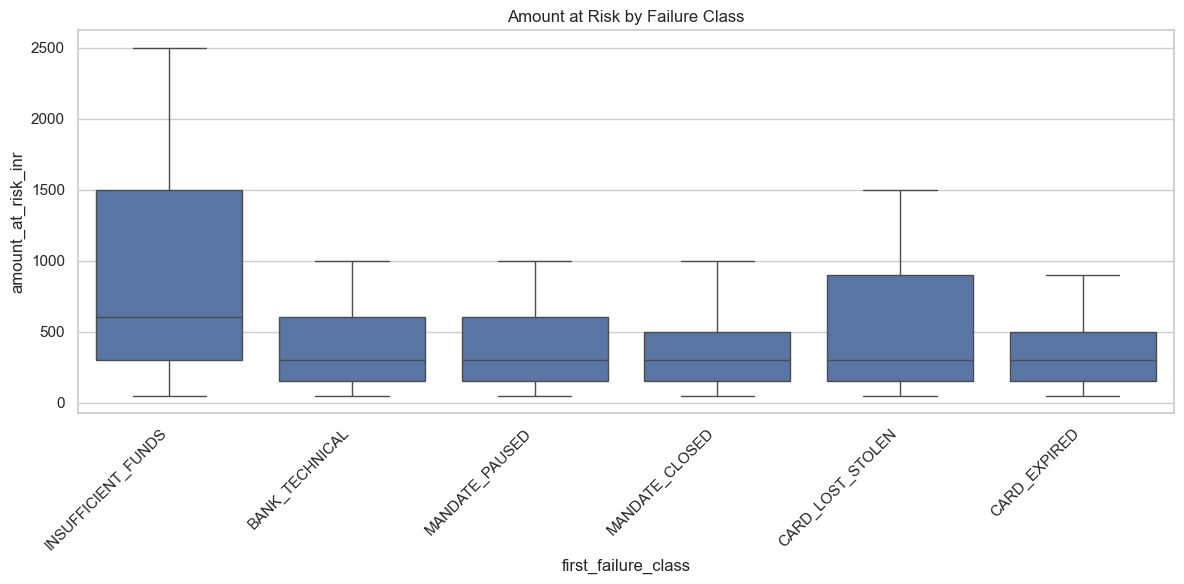


EDA INSIGHT
section: Recovery Case Behaviour
finding: Amount-at-risk distributions differ across failure classes.
evidence: Failure-class median spread = 300.00 INR.
statistical_support: Distribution comparison using ECDF and median summaries.
interpretation: Different failure mechanisms expose the recovery system to different economic distributions.
ml_implication: Failure class and amount should remain separate candidate variables; their interaction should be examined in C3.
caveat: Exploratory association; not a causal treatment estimate.


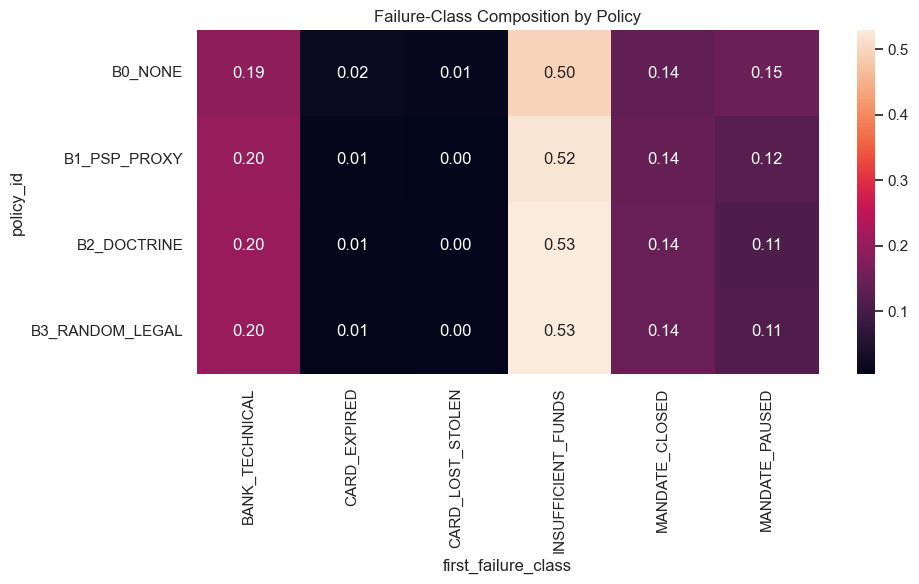


EDA INSIGHT
section: Policy Selection Exposure
finding: Policy assignment and failure-class composition were compared.
evidence: Chi-square=672.069, p=1.6595e-133, dof=15.
statistical_support: Chi-square test of policy × failure-class association.
interpretation: The test describes whether policy exposure and failure-class composition are associated.
ml_implication: Action/policy analyses should preserve state conditioning and support information rather than comparing raw averages only.
caveat: Exploratory association; not a causal treatment estimate.


In [19]:

cases = dfs["recovery_cases"]

amount_col = next(
    (c for c in ["amount_at_risk", "amount_at_risk_inr"] if c in cases.columns),
    None
)

failure_col = next(
    (c for c in ["first_failure_class", "failure_class"] if c in cases.columns),
    None
)

if amount_col and failure_col:

    plt.figure(figsize=(12, 6))
    sns.ecdfplot(
        data=cases,
        x=amount_col,
        hue=failure_col,
    )
    plt.title("ECDF of Amount at Risk by Failure Class")
    save_plot("ecdf_amount_at_risk_by_failure_class.png")

    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=cases,
        x=failure_col,
        y=amount_col,
        showfliers=False,
    )
    plt.title("Amount at Risk by Failure Class")
    plt.xticks(rotation=45, ha="right")
    save_plot("boxplot_amount_at_risk_by_failure_class.png")

    medians = cases.groupby(failure_col)[amount_col].median()
    spread = float(medians.max() - medians.min())

    record_insight(
        section="Recovery Case Behaviour",
        finding="Amount-at-risk distributions differ across failure classes.",
        evidence=f"Failure-class median spread = {spread:.2f} INR.",
        statistical_support="Distribution comparison using ECDF and median summaries.",
        interpretation=(
            "Different failure mechanisms expose the recovery system to different "
            "economic distributions."
        ),
        ml_implication=(
            "Failure class and amount should remain separate candidate variables; "
            "their interaction should be examined in C3."
        ),
    )

# Policy exposure against failure mechanism
if {
    "policy_id",
    "first_failure_class",
}.issubset(cases.columns):

    policy_failure = pd.crosstab(
        cases["policy_id"],
        cases["first_failure_class"],
        normalize="index",
    )

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        policy_failure,
        annot=True,
        fmt=".2f",
    )
    plt.title("Failure-Class Composition by Policy")
    save_plot("policy_failure_class_heatmap.png")

    observed_counts = pd.crosstab(
        cases["policy_id"],
        cases["first_failure_class"],
    )

    if observed_counts.shape[0] >= 2 and observed_counts.shape[1] >= 2:
        chi2, p, dof, expected = stats.chi2_contingency(
            observed_counts
        )

        record_insight(
            section="Policy Selection Exposure",
            finding="Policy assignment and failure-class composition were compared.",
            evidence=(
                f"Chi-square={chi2:.3f}, p={p:.4e}, "
                f"dof={dof}."
            ),
            statistical_support=(
                "Chi-square test of policy × failure-class association."
            ),
            interpretation=(
                "The test describes whether policy exposure and failure-class "
                "composition are associated."
            ),
            ml_implication=(
                "Action/policy analyses should preserve state conditioning and "
                "support information rather than comparing raw averages only."
            ),
        )


## 3. Action Selection and Intervention Dynamics

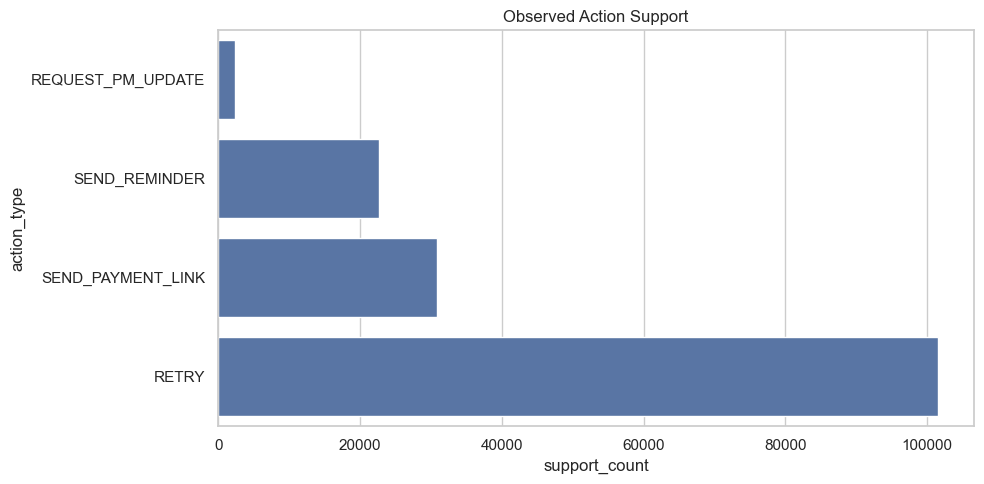

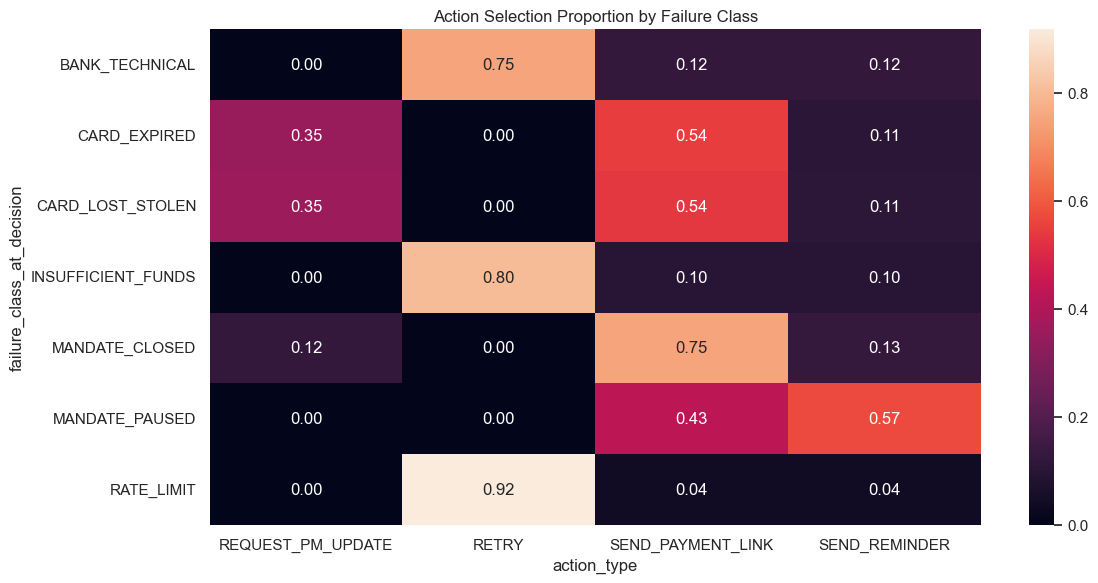

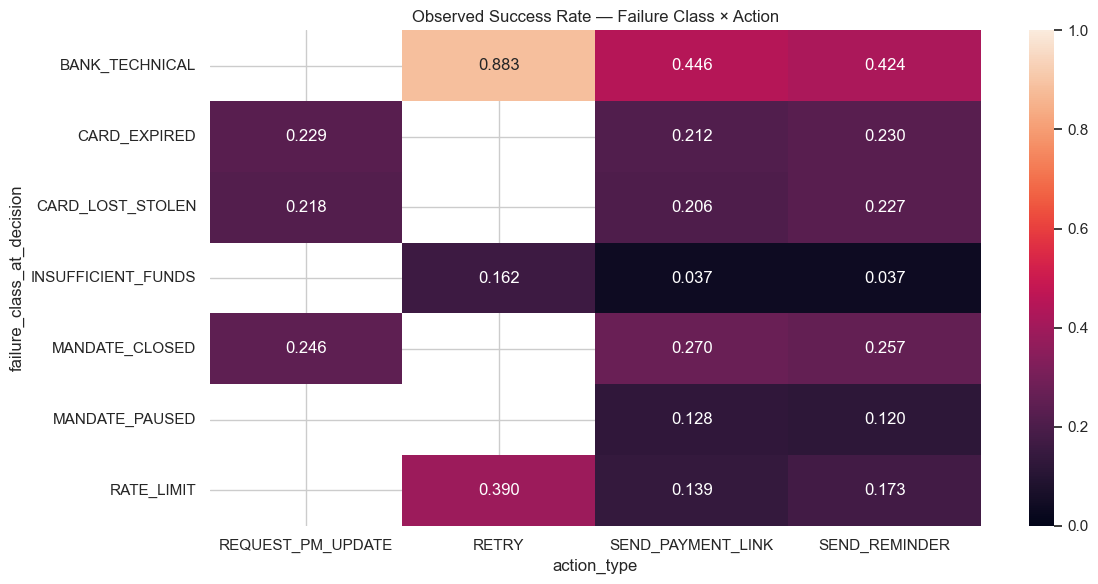


EDA INSIGHT
section: Intervention Dynamics
finding: Observed action success varies across actions within some failure states.
evidence: Largest supported within-state success-rate spread = 0.460 in `BANK_TECHNICAL`.
statistical_support: Grouped observed success rates with minimum support threshold.
interpretation: The usefulness of an intervention appears state-dependent in the logged synthetic environment.
ml_implication: The propensity model should retain both state and action and allow their interaction.
caveat: Exploratory association; not a causal treatment estimate.


In [20]:

if "action_type" in df_ml.columns:
    overall_action = (
        df_ml["action_type"]
        .value_counts(dropna=False)
        .rename("support_count")
        .reset_index()
    )
    overall_action.columns = ["action_type", "support_count"]

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=overall_action.sort_values("support_count"),
        x="support_count",
        y="action_type",
        errorbar=None,
    )
    plt.title("Observed Action Support")
    save_plot("action_support.png")

if {
    "failure_class_at_decision",
    "action_type",
}.issubset(df_ml.columns):

    action_failure = pd.crosstab(
        df_ml["failure_class_at_decision"],
        df_ml["action_type"],
        normalize="index",
    )

    plt.figure(figsize=(12, 6))
    sns.heatmap(
        action_failure,
        annot=True,
        fmt=".2f",
    )
    plt.title("Action Selection Proportion by Failure Class")
    save_plot("action_selection_by_failure_class.png")

    if target_col:
        success = (
            df_ml.groupby(
                ["failure_class_at_decision", "action_type"],
                dropna=False,
            )[target_col]
            .agg(observations="size", observed_success_rate="mean")
            .reset_index()
        )

        success = success[
            success["observations"] >= 30
        ]

        pivot = success.pivot(
            index="failure_class_at_decision",
            columns="action_type",
            values="observed_success_rate",
        )

        plt.figure(figsize=(12, 6))
        sns.heatmap(
            pivot,
            annot=True,
            fmt=".3f",
            vmin=0,
            vmax=1,
        )
        plt.title("Observed Success Rate — Failure Class × Action")
        save_plot("observed_success_failure_class_action.png")

        if not pivot.empty:
            row_gap = pivot.max(axis=1) - pivot.min(axis=1)
            row_gap = row_gap.dropna()

            if not row_gap.empty:
                state = row_gap.idxmax()
                gap = float(row_gap.max())

                record_insight(
                    section="Intervention Dynamics",
                    finding=(
                        f"Observed action success varies across actions "
                        f"within some failure states."
                    ),
                    evidence=(
                        f"Largest supported within-state success-rate spread "
                        f"= {gap:.3f} in `{state}`."
                    ),
                    statistical_support=(
                        "Grouped observed success rates with minimum support threshold."
                    ),
                    interpretation=(
                        "The usefulness of an intervention appears state-dependent "
                        "in the logged synthetic environment."
                    ),
                    ml_implication=(
                        "The propensity model should retain both state and action "
                        "and allow their interaction."
                    ),
                )


## 4. Rail, Value Tier and Policy × Action Interactions

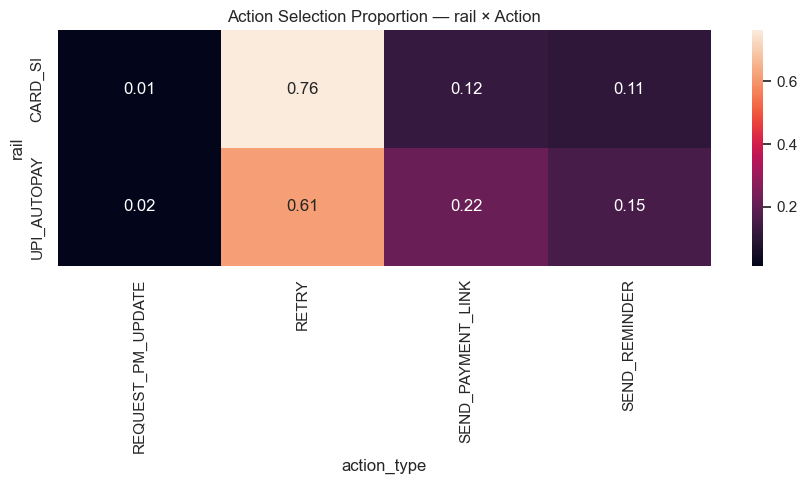

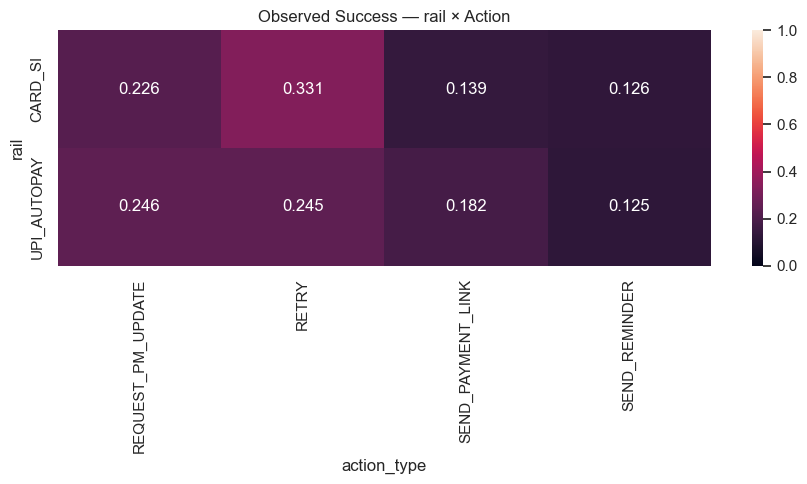

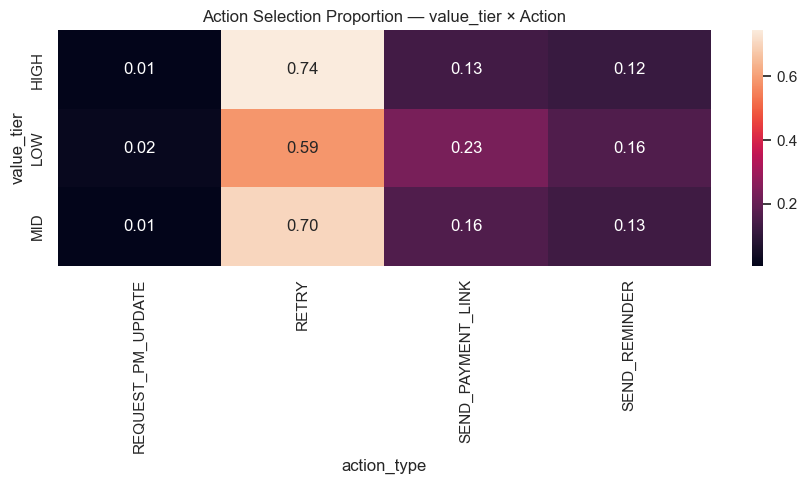

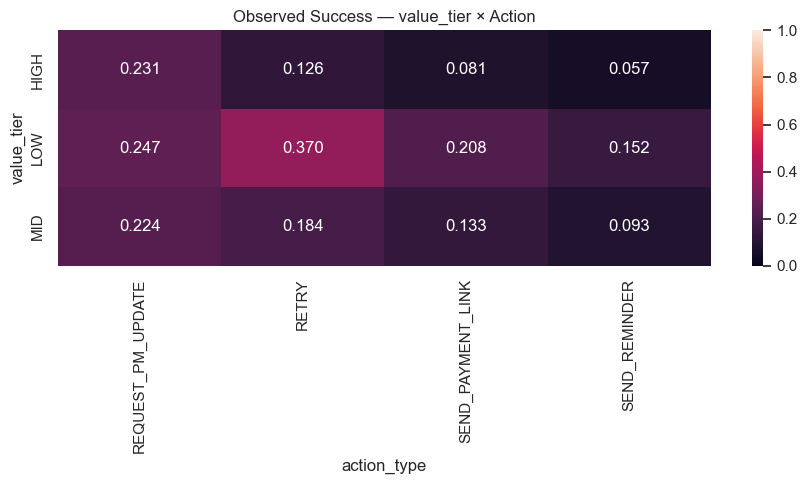

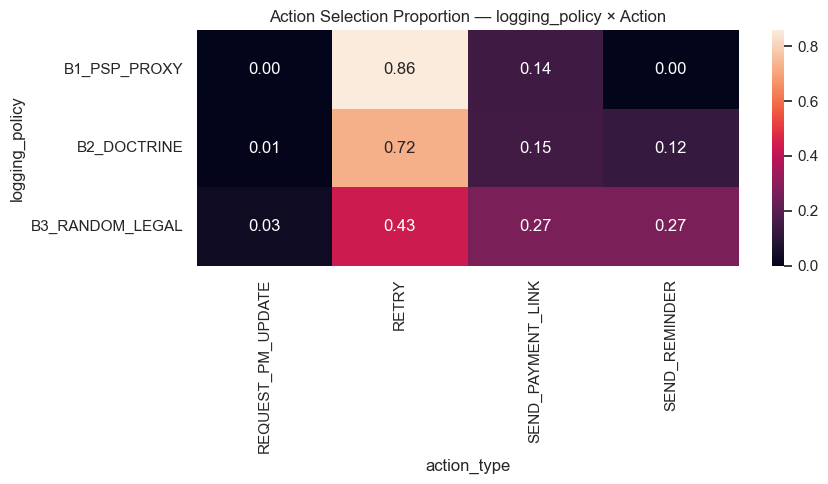

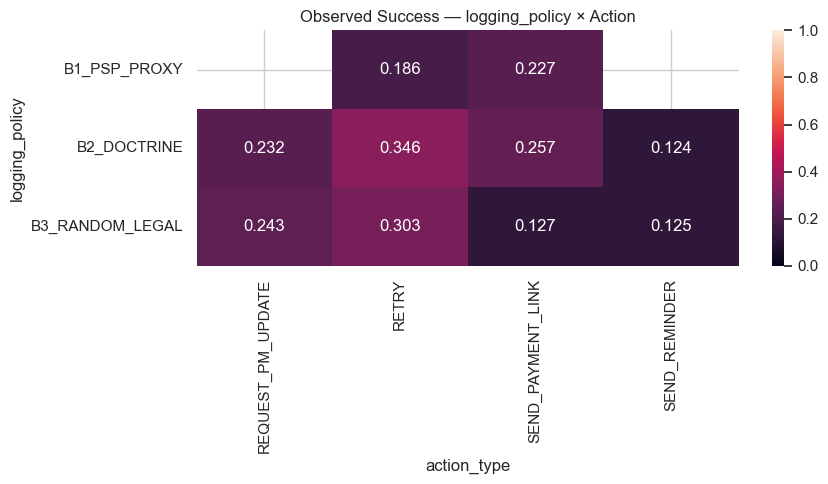

In [21]:

interaction_specs = [
    ("rail", "action_type"),
    ("value_tier", "action_type"),
    ("logging_policy", "action_type"),
]

for state_col, action_col in interaction_specs:

    if not {state_col, action_col}.issubset(df_ml.columns):
        continue

    selection = pd.crosstab(
        df_ml[state_col],
        df_ml[action_col],
        normalize="index",
    )

    plt.figure(
        figsize=(
            max(9, selection.shape[1] * 1.3),
            max(5, selection.shape[0] * 0.5),
        )
    )
    sns.heatmap(
        selection,
        annot=True,
        fmt=".2f",
    )
    plt.title(
        f"Action Selection Proportion — {state_col} × Action"
    )
    save_plot(
        f"action_selection_{state_col}.png"
    )

    success = (
        df_ml.groupby(
            [state_col, action_col],
            dropna=False,
        )[target_col]
        .agg(observations="size", observed_success_rate="mean")
        .reset_index()
    )
    success = success[success["observations"] >= 30]

    if success.empty:
        continue

    pivot = success.pivot(
        index=state_col,
        columns=action_col,
        values="observed_success_rate",
    )

    plt.figure(
        figsize=(
            max(9, pivot.shape[1] * 1.3),
            max(5, pivot.shape[0] * 0.5),
        )
    )
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".3f",
        vmin=0,
        vmax=1,
    )
    plt.title(
        f"Observed Success — {state_col} × Action"
    )
    save_plot(
        f"observed_success_{state_col}_action.png"
    )


## 5. Nonlinear Numeric Feature Relationships

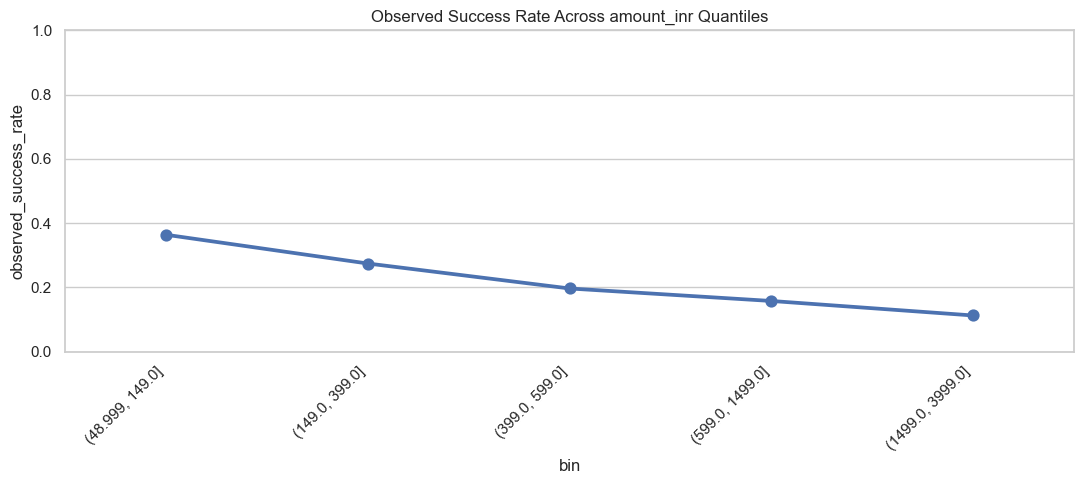

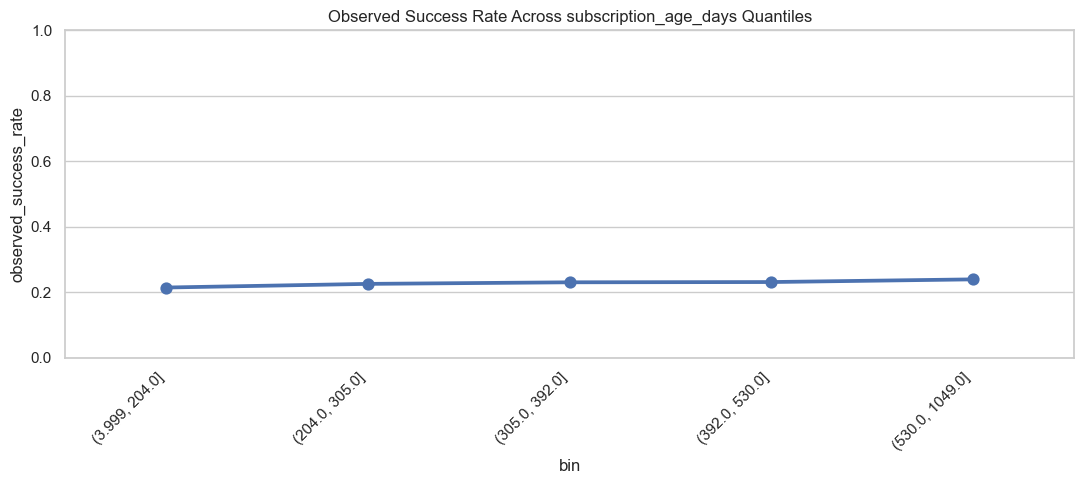

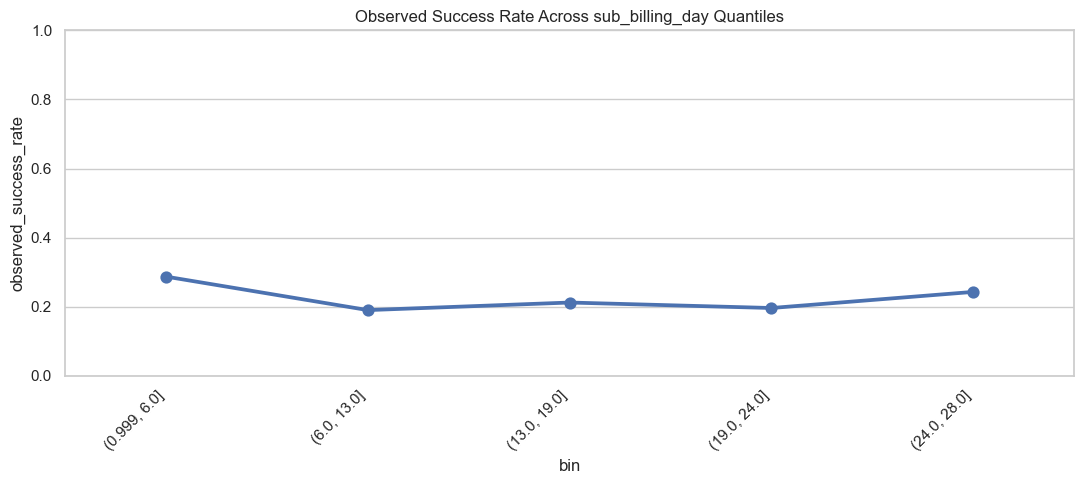

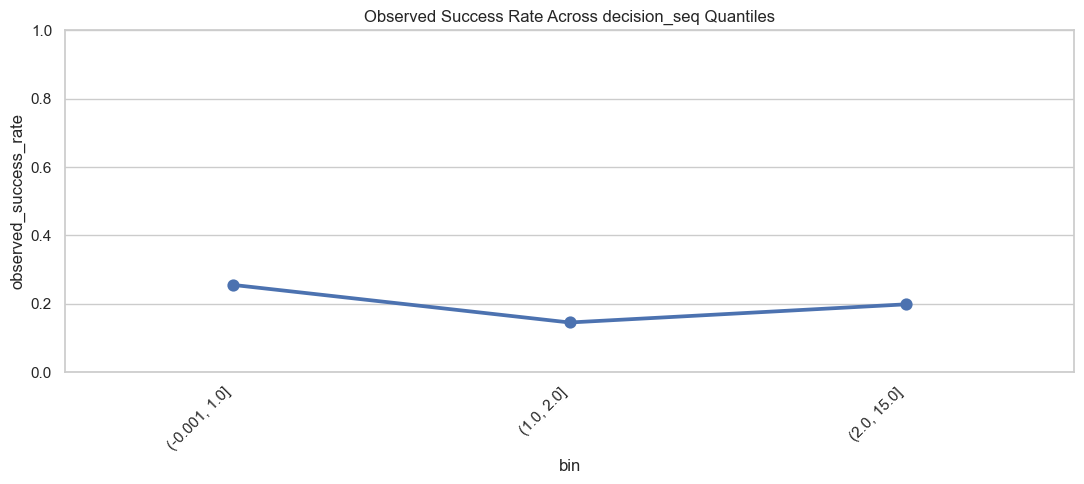

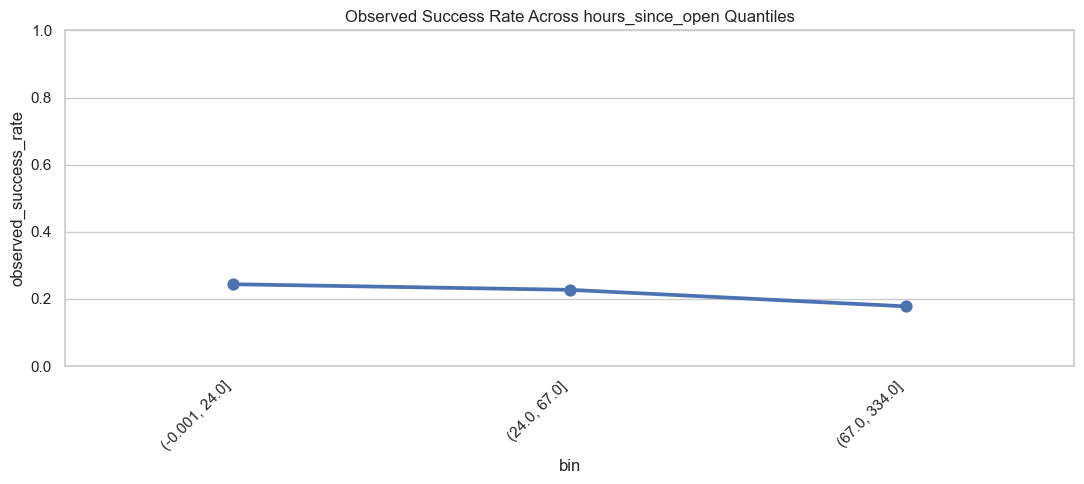

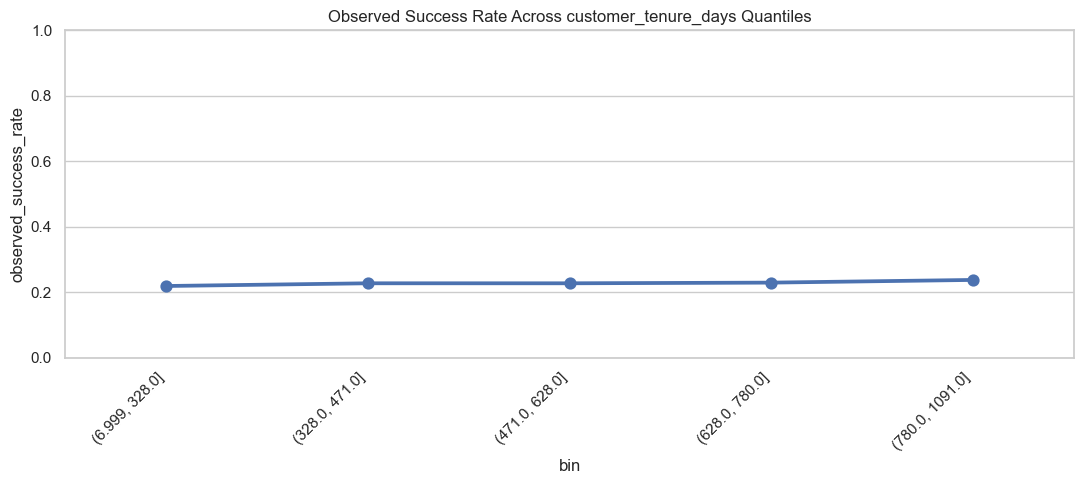

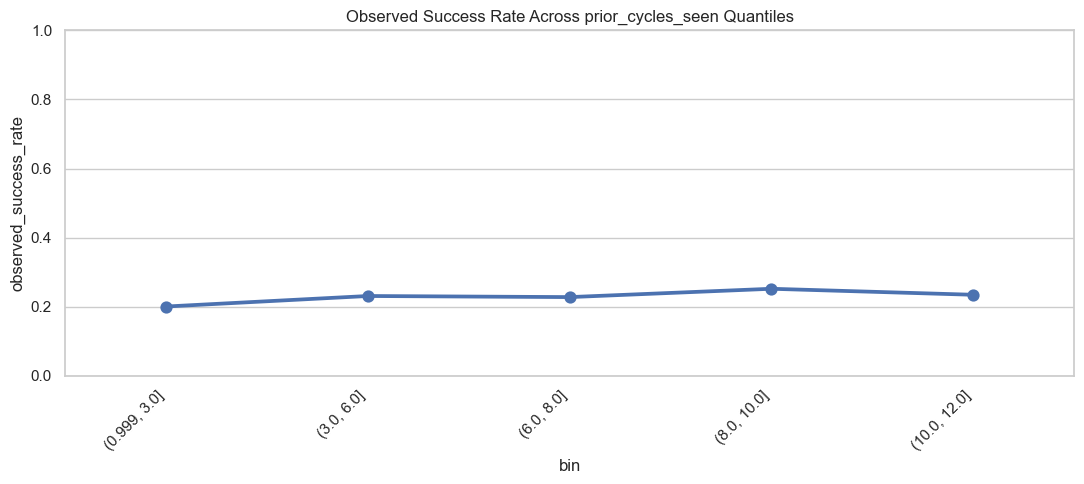

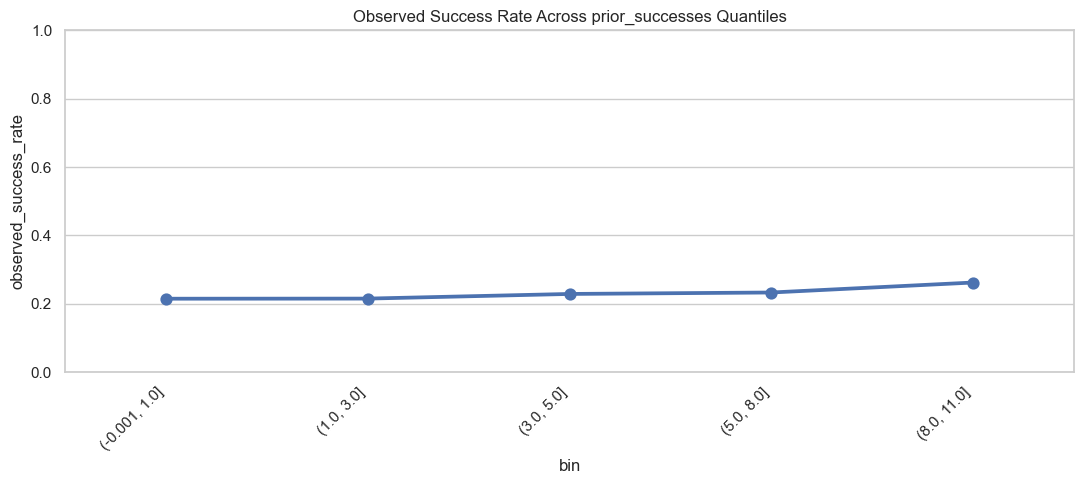

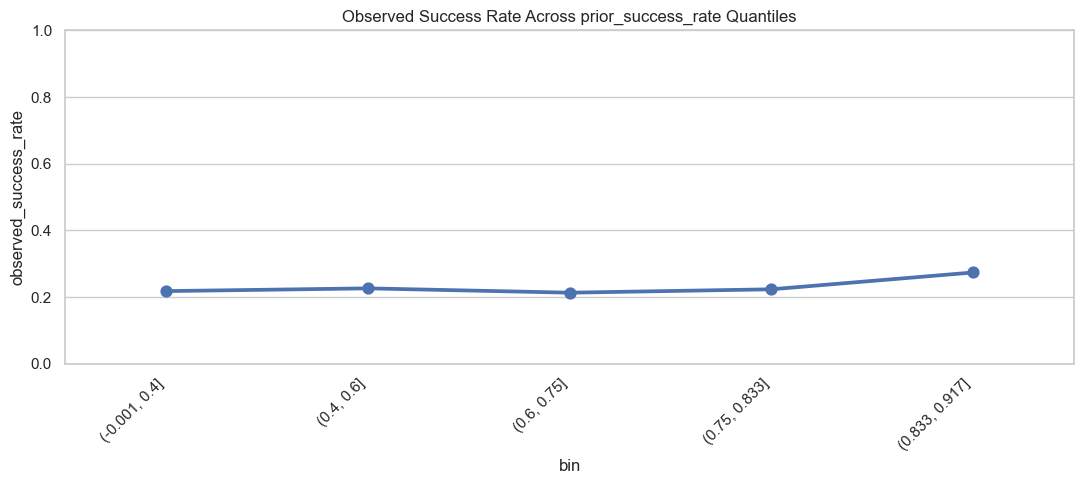

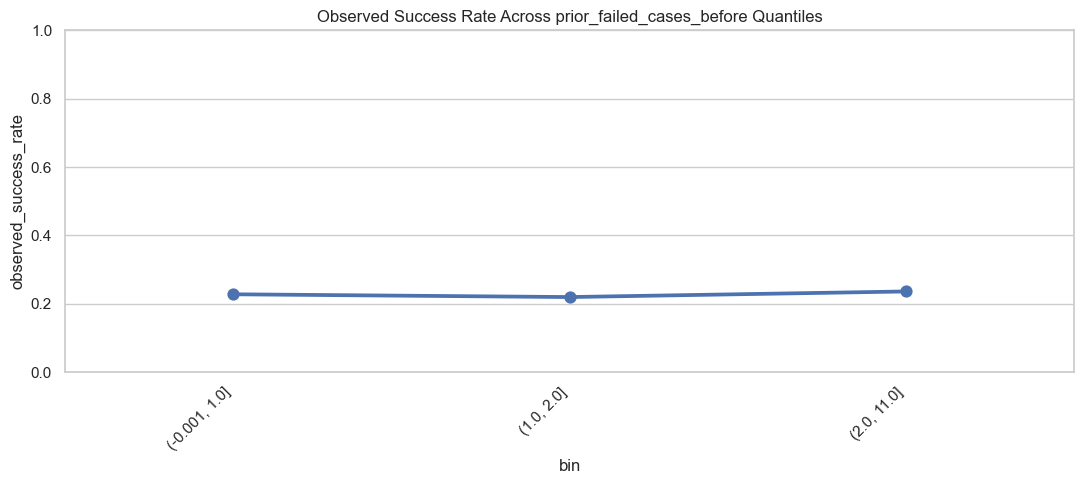

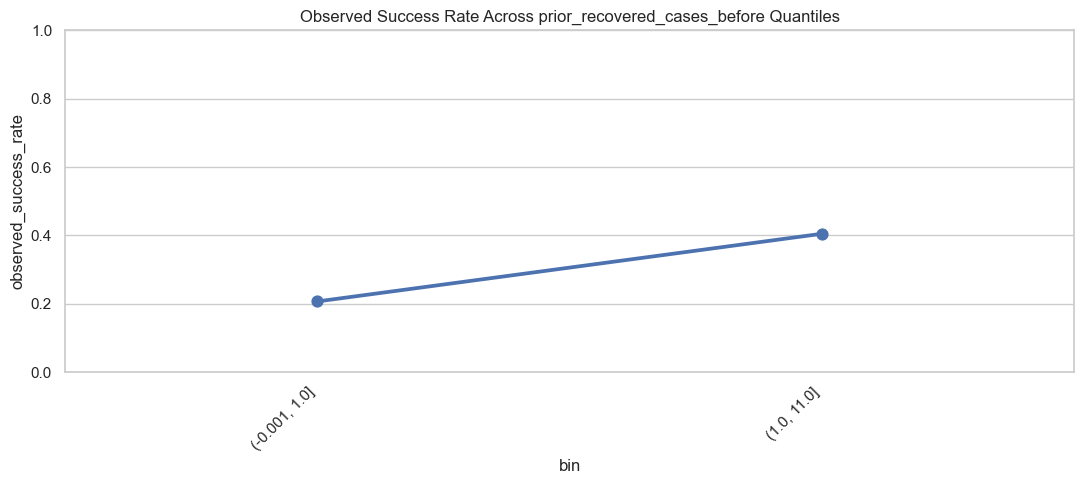

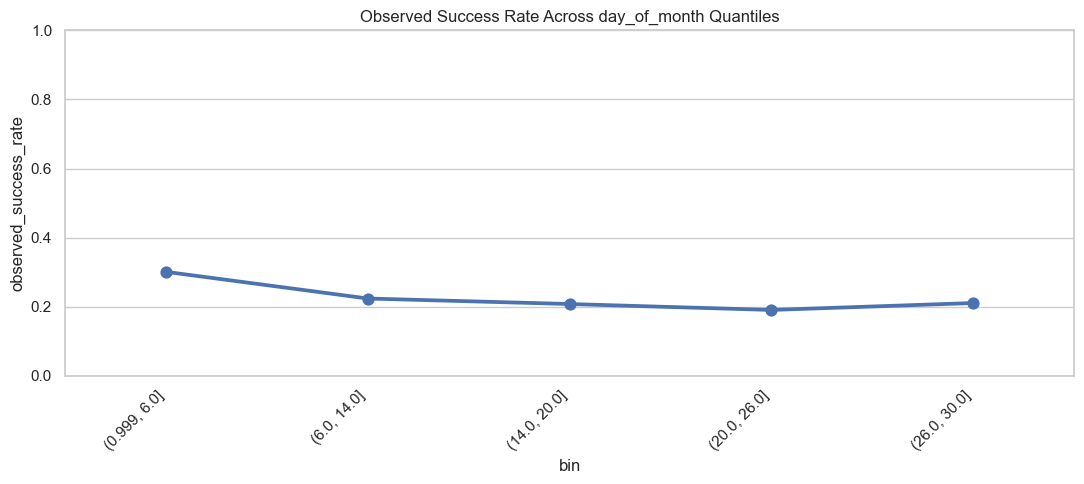

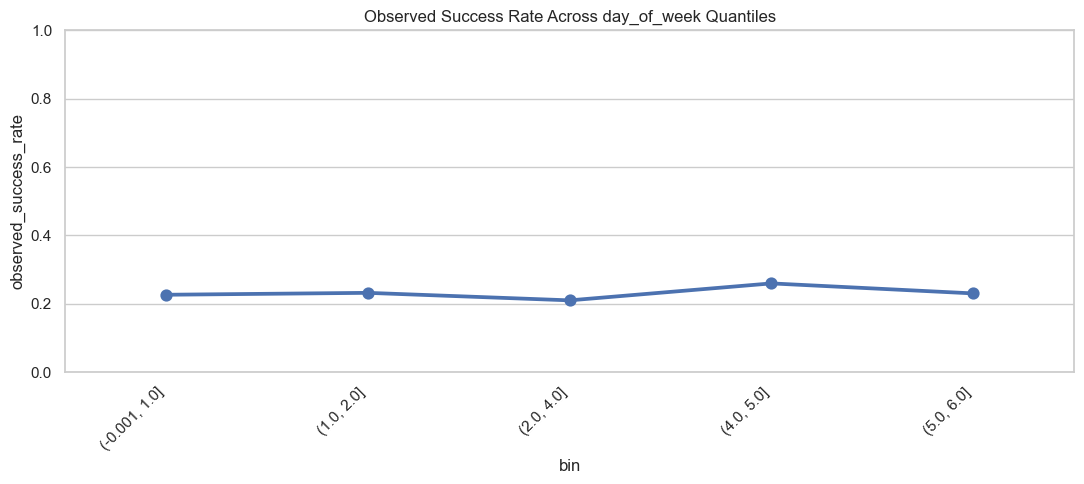

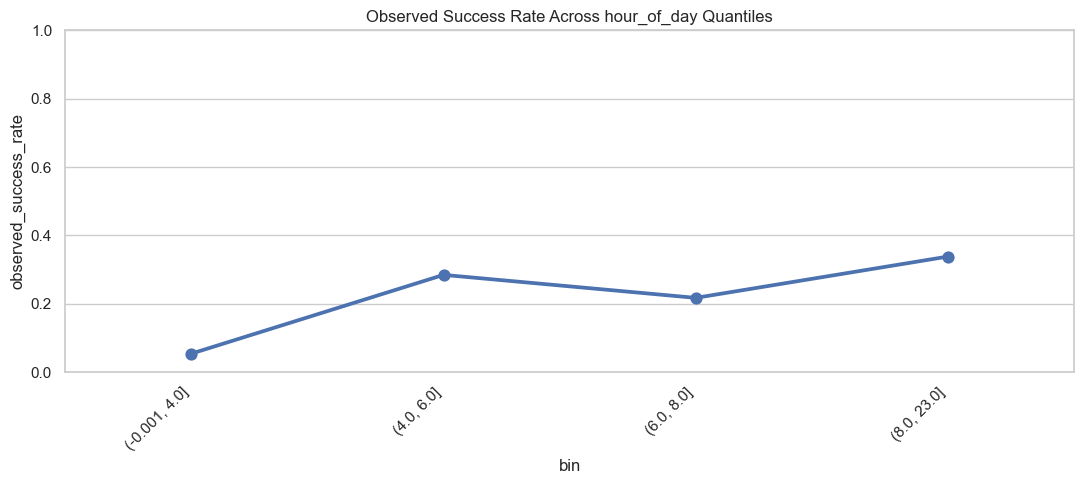

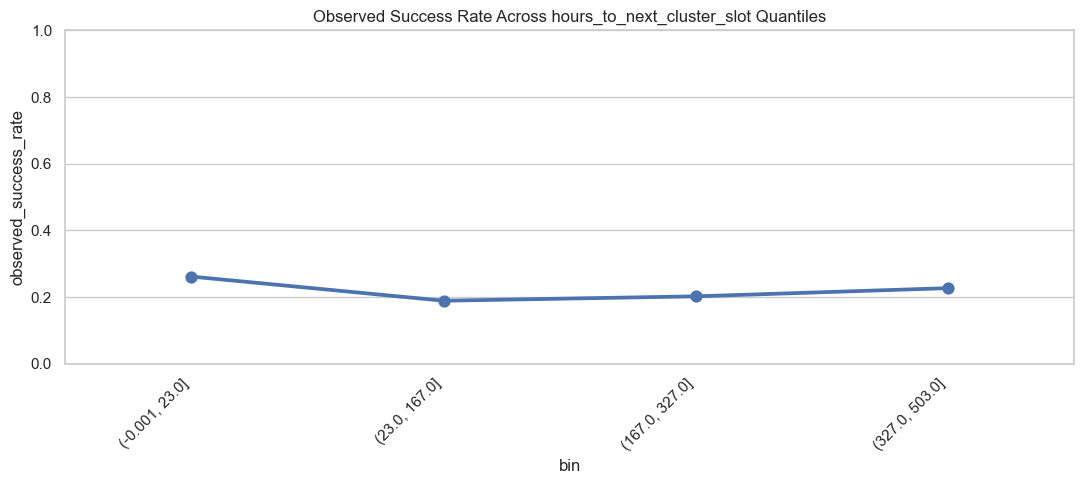

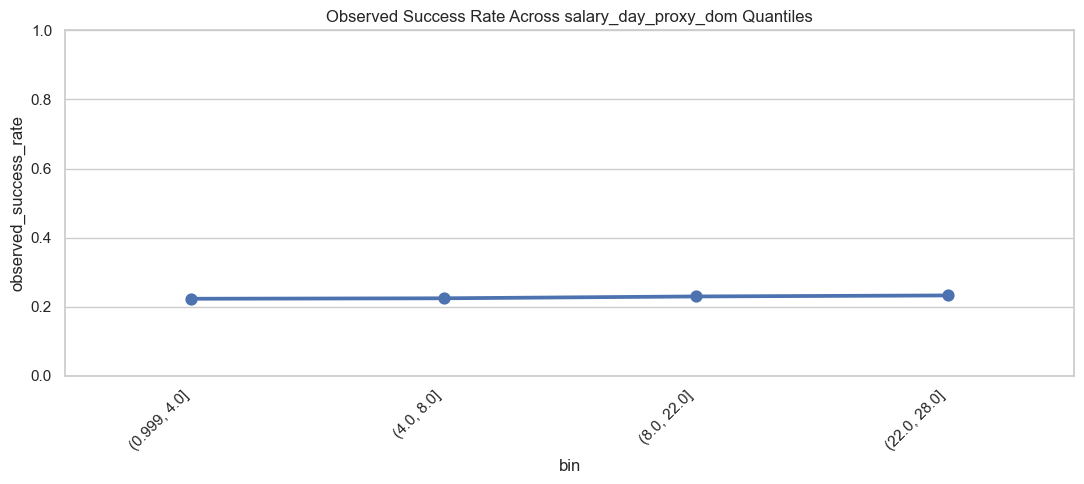

,feature,binned_success_rate_spread
13,hour_of_day,0.284038
0,amount_inr,0.251218
10,prior_recovered_cases_before,0.197960
11,day_of_month,0.110276
3,decision_seq,0.109915
2,sub_billing_day,0.096915
14,hours_to_next_cluster_slot,0.072467
4,hours_since_open,0.065914
8,prior_success_rate,0.060620
6,prior_cycles_seen,0.051364



EDA INSIGHT
section: Nonlinear Feature Behaviour
finding: hour_of_day shows variation in observed success across quantile bins.
evidence: Max-minus-min binned success-rate spread = 0.284.
statistical_support: Quantile-binned observed success rates.
interpretation: A nonlinear relationship may exist and should not be summarized by a simple linear correlation alone.
ml_implication: Keep as a C3 candidate and test an appropriate representation.
caveat: Exploratory association; not a causal treatment estimate.

EDA INSIGHT
section: Nonlinear Feature Behaviour
finding: amount_inr shows variation in observed success across quantile bins.
evidence: Max-minus-min binned success-rate spread = 0.251.
statistical_support: Quantile-binned observed success rates.
interpretation: A nonlinear relationship may exist and should not be summarized by a simple linear correlation alone.
ml_implication: Keep as a C3 candidate and test an appropriate representation.
caveat: Exploratory association; not a ca

In [22]:

numeric_candidate_cols = []

for col in candidate_cols:
    s = df_ml[col]
    if (
        pd.api.types.is_numeric_dtype(s)
        and not pd.api.types.is_bool_dtype(s)
    ):
        numeric_candidate_cols.append(col)

numeric_relationships = []

for col in numeric_candidate_cols:

    binned = qbin_table(df_ml, col, q=5)

    if binned is None or len(binned) < 2:
        continue

    plt.figure(figsize=(11, 5))
    sns.pointplot(
        data=binned,
        x="bin",
        y="observed_success_rate",
    )
    plt.ylim(0, 1)
    plt.title(
        f"Observed Success Rate Across {col} Quantiles"
    )
    plt.xticks(rotation=45, ha="right")
    save_plot(
        f"nonlinear_{col}.png"
    )

    spread = float(
        binned["observed_success_rate"].max()
        - binned["observed_success_rate"].min()
    )

    numeric_relationships.append({
        "feature": col,
        "binned_success_rate_spread": spread,
    })

if numeric_relationships:
    nonlinear_df = pd.DataFrame(
        numeric_relationships
    ).sort_values(
        "binned_success_rate_spread",
        ascending=False,
    )
    display(nonlinear_df)

    nonlinear_df.to_csv(
        REPORT_DIR / "numeric_nonlinear_relationships.csv",
        index=False,
    )

    for _, row in nonlinear_df.head(10).iterrows():
        if row["binned_success_rate_spread"] <= 0:
            continue

        record_insight(
            section="Nonlinear Feature Behaviour",
            finding=(
                f"{row['feature']} shows variation in observed success "
                "across quantile bins."
            ),
            evidence=(
                f"Max-minus-min binned success-rate spread = "
                f"{row['binned_success_rate_spread']:.3f}."
            ),
            statistical_support=(
                "Quantile-binned observed success rates."
            ),
            interpretation=(
                "A nonlinear relationship may exist and should not be "
                "summarized by a simple linear correlation alone."
            ),
            ml_implication=(
                "Keep as a C3 candidate and test an appropriate representation."
            ),
        )


## 6. Salary / Timing Proxy Deep Dive

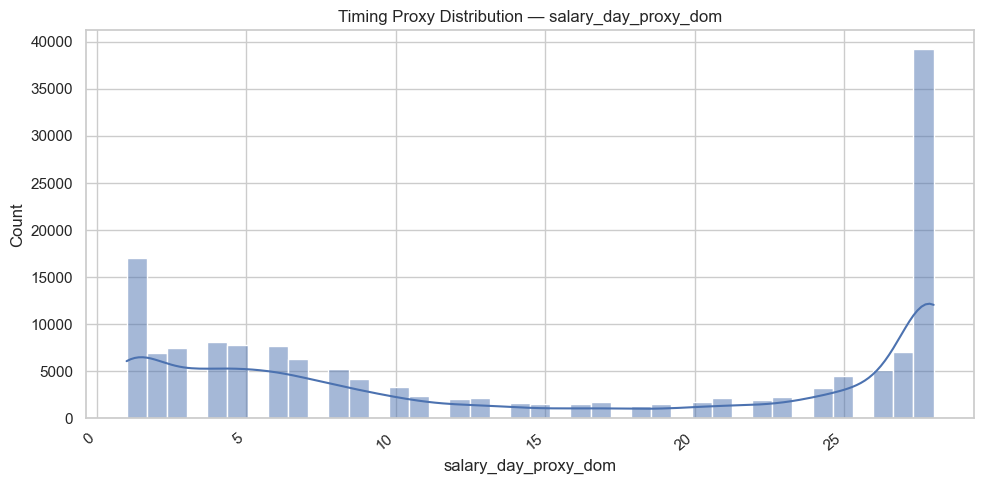

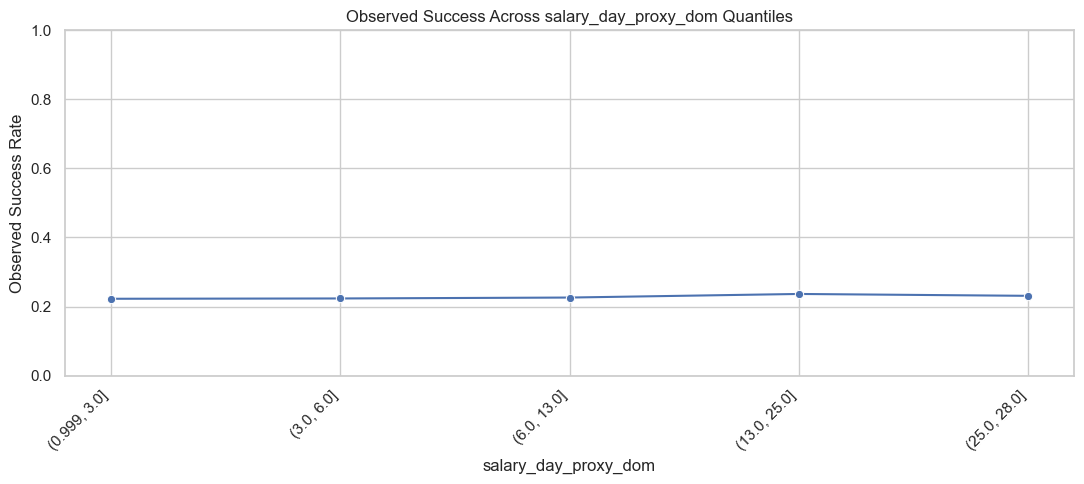


Observed success by salary_day_proxy_dom:


,bin_label,observations,observed_success_rate
0,"(0.999, 3.0]",31437,0.222413
1,"(3.0, 6.0]",23629,0.223285
2,"(6.0, 13.0]",25759,0.225940
3,"(13.0, 25.0]",25188,0.236343
4,"(25.0, 28.0]",51410,0.230928


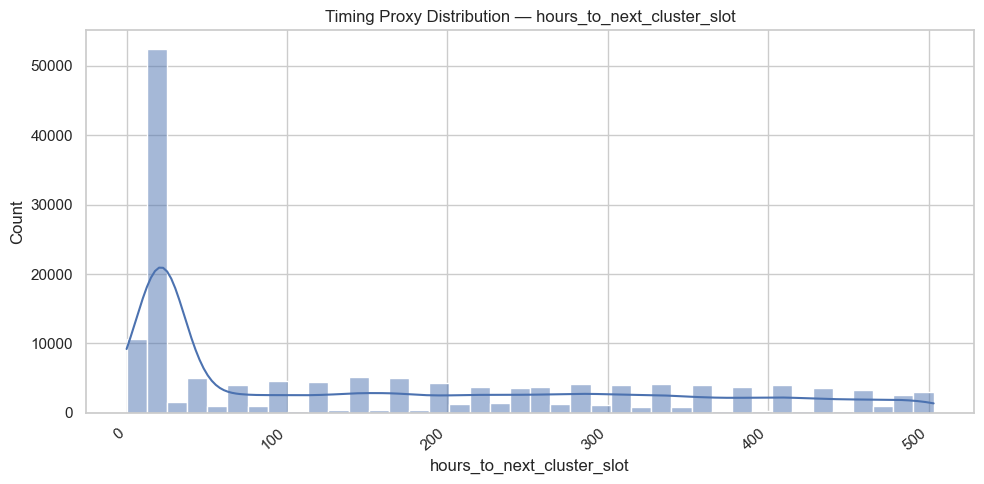

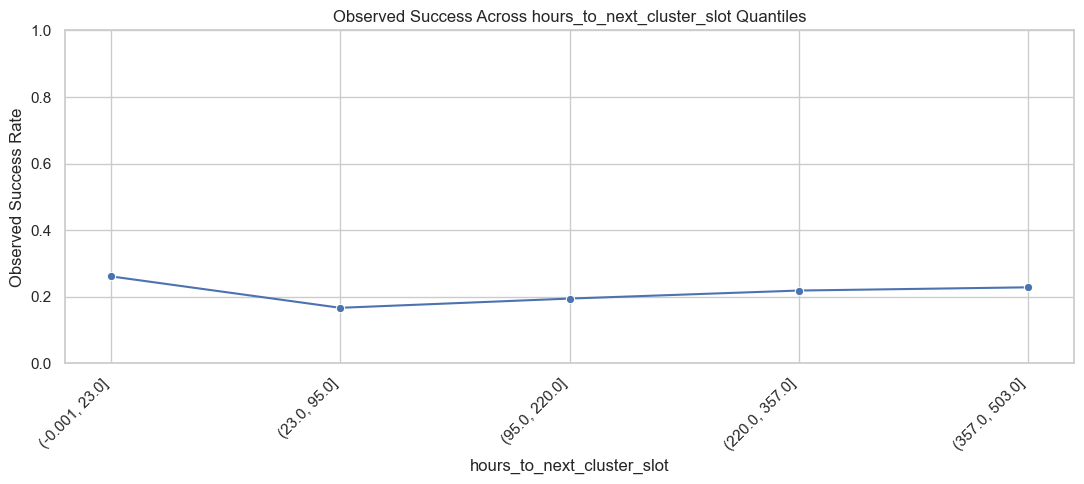


Observed success by hours_to_next_cluster_slot:


,bin_label,observations,observed_success_rate
0,"(-0.001, 23.0]",63065,0.261429
1,"(23.0, 95.0]",16102,0.166998
2,"(95.0, 220.0]",26423,0.194717
3,"(220.0, 357.0]",26207,0.218835
4,"(357.0, 503.0]",25626,0.228557


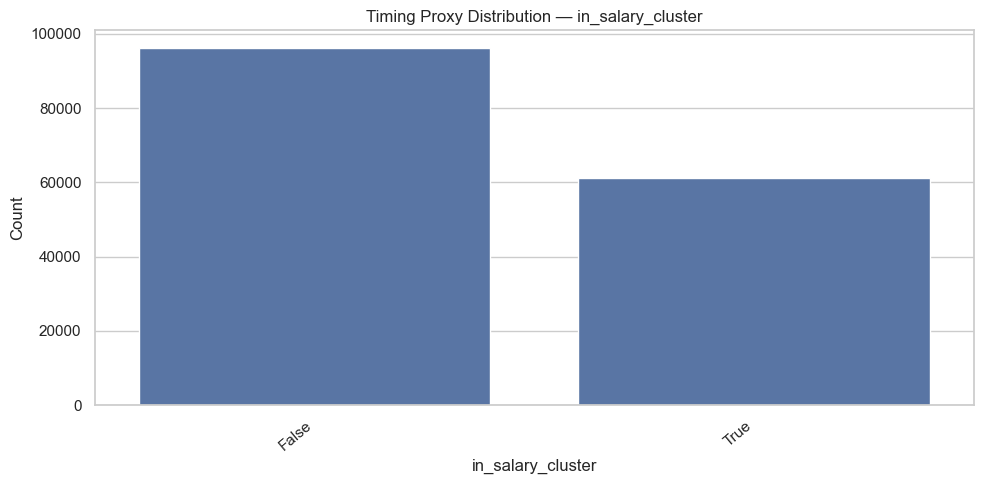

In [23]:
# ============================================================
# 6. SALARY / TIMING PROXY DEEP DIVE
# ============================================================

timing_candidates = [
    "proxy_days_to_salary",
    "salary_day_proxy_dom",
    "hours_to_next_cluster_slot",
    "time_since_first_failure_days",
    "tenure_months",
    "in_salary_cluster",
]

for col in timing_candidates:

    if col not in df_ml.columns:
        continue

    # --------------------------------------------------------
    # 1. Distribution
    # --------------------------------------------------------
    is_numeric = (
        pd.api.types.is_numeric_dtype(df_ml[col])
        and not pd.api.types.is_bool_dtype(df_ml[col])
    )

    if is_numeric:
        plt.figure(figsize=(10, 5))

        sns.histplot(
            data=df_ml,
            x=col,
            bins=40,
            kde=True,
        )

        plt.title(f"Timing Proxy Distribution — {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=40, ha="right")

        save_plot(
            f"timing_distribution_{col}.png"
        )

    else:
        plt.figure(figsize=(10, 5))

        sns.countplot(
            data=df_ml,
            x=col,
        )

        plt.title(f"Timing Proxy Distribution — {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=40, ha="right")

        save_plot(
            f"timing_distribution_{col}.png"
        )

    # --------------------------------------------------------
    # 2. Observed success across quantile bins
    # --------------------------------------------------------
    if (
        is_numeric
        and df_ml[col].nunique(dropna=True) > 8
    ):

        temp = df_ml[
            [col, target_col]
        ].dropna().copy()

        if len(temp) >= 100:

            try:
                temp["bin"] = pd.qcut(
                    temp[col],
                    q=6,
                    duplicates="drop",
                )

                grouped = (
                    temp.groupby(
                        "bin",
                        observed=False,
                    )[target_col]
                    .agg(
                        observations="size",
                        observed_success_rate="mean",
                    )
                    .reset_index()
                )

                grouped = grouped[
                    grouped["observations"] >= 30
                ].copy()

                if len(grouped) >= 2:

                    # Convert pandas Interval objects to strings
                    # before passing them to Seaborn.
                    grouped["bin_label"] = (
                        grouped["bin"]
                        .astype(str)
                    )

                    plt.figure(
                        figsize=(11, 5)
                    )

                    sns.lineplot(
                        data=grouped,
                        x="bin_label",
                        y="observed_success_rate",
                        marker="o",
                    )

                    plt.ylim(0, 1)

                    plt.title(
                        f"Observed Success Across "
                        f"{col} Quantiles"
                    )

                    plt.xlabel(col)
                    plt.ylabel(
                        "Observed Success Rate"
                    )

                    plt.xticks(
                        rotation=45,
                        ha="right",
                    )

                    save_plot(
                        f"timing_success_{col}.png"
                    )

                    # Optional evidence printout
                    print(
                        f"\nObserved success by {col}:"
                    )

                    display(
                        grouped[
                            [
                                "bin_label",
                                "observations",
                                "observed_success_rate",
                            ]
                        ]
                    )

            except Exception as exc:

                print(
                    f"Timing quantile analysis skipped "
                    f"for {col}: {exc}"
                )


# ============================================================
# 3. DEDICATED ACTION × SALARY PROXY ANALYSIS
# ============================================================

if {
    "action_type",
    "proxy_days_to_salary",
}.issubset(df_ml.columns):

    temp = df_ml[
        [
            "action_type",
            "proxy_days_to_salary",
            target_col,
        ]
    ].dropna().copy()

    if (
        len(temp) >= 100
        and temp["proxy_days_to_salary"]
        .nunique(dropna=True) >= 8
    ):

        try:

            temp["salary_bin"] = pd.qcut(
                temp["proxy_days_to_salary"],
                q=6,
                duplicates="drop",
            )

            grouped = (
                temp.groupby(
                    [
                        "salary_bin",
                        "action_type",
                    ],
                    observed=False,
                )[target_col]
                .agg(
                    observations="size",
                    observed_success_rate="mean",
                )
                .reset_index()
            )

            # Remove very small cells so heatmap does not
            # overinterpret extremely sparse combinations.
            grouped = grouped[
                grouped["observations"] >= 30
            ].copy()

            if not grouped.empty:

                # Convert Interval index to strings.
                grouped["salary_bin_label"] = (
                    grouped["salary_bin"]
                    .astype(str)
                )

                pivot = grouped.pivot(
                    index="salary_bin_label",
                    columns="action_type",
                    values="observed_success_rate",
                )

                if not pivot.empty:

                    plt.figure(
                        figsize=(
                            max(
                                9,
                                pivot.shape[1] * 1.3
                            ),
                            6,
                        )
                    )

                    sns.heatmap(
                        pivot,
                        annot=True,
                        fmt=".3f",
                        vmin=0,
                        vmax=1,
                    )

                    plt.title(
                        "Observed Success — "
                        "Salary Proximity × Action"
                    )

                    plt.xlabel(
                        "Action Type"
                    )

                    plt.ylabel(
                        "Salary-Proximity Bin"
                    )

                    save_plot(
                        "salary_proximity_action_success.png"
                    )

                    print(
                        "\nObserved success by "
                        "salary proximity × action:"
                    )

                    display(
                        grouped[
                            [
                                "salary_bin_label",
                                "action_type",
                                "observations",
                                "observed_success_rate",
                            ]
                        ]
                        .sort_values(
                            [
                                "salary_bin_label",
                                "observed_success_rate",
                            ],
                            ascending=[True, False],
                        )
                    )

        except Exception as exc:

            print(
                "Salary × action analysis skipped:",
                exc,
            )

## 7. Target-Stratified Distributions

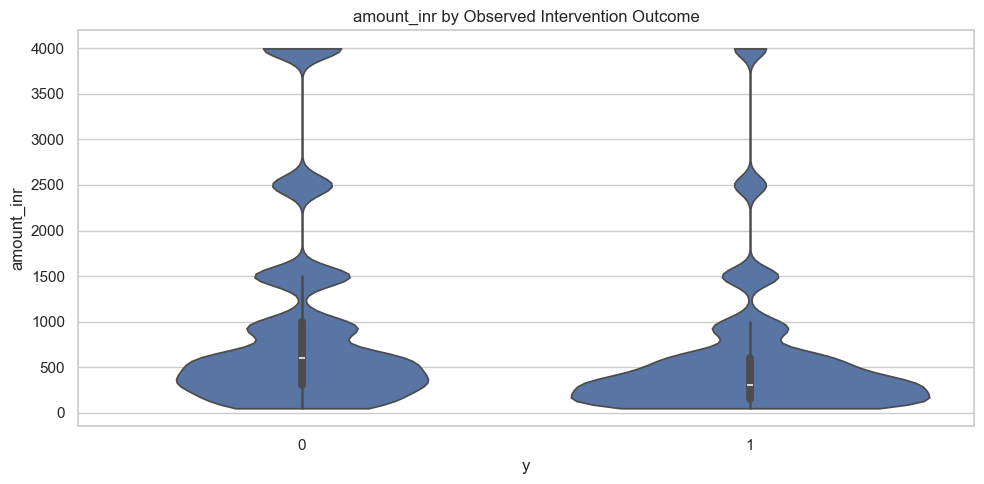


EDA INSIGHT
section: Target-Stratified Feature Behaviour
finding: amount_inr differs between observed outcome groups.
evidence: Median y=1: 299; median y=0: 599.
statistical_support: Mann-Whitney U=1572658717.00, p=0.0000e+00, rank-biserial effect size≈0.279.
interpretation: The feature distributions show an observed difference between successful and unsuccessful intervention records.
ml_implication: amount_inr remains a candidate signal for C3, subject to decision-time availability, stability and leakage review.
caveat: Exploratory association; not a causal treatment estimate.


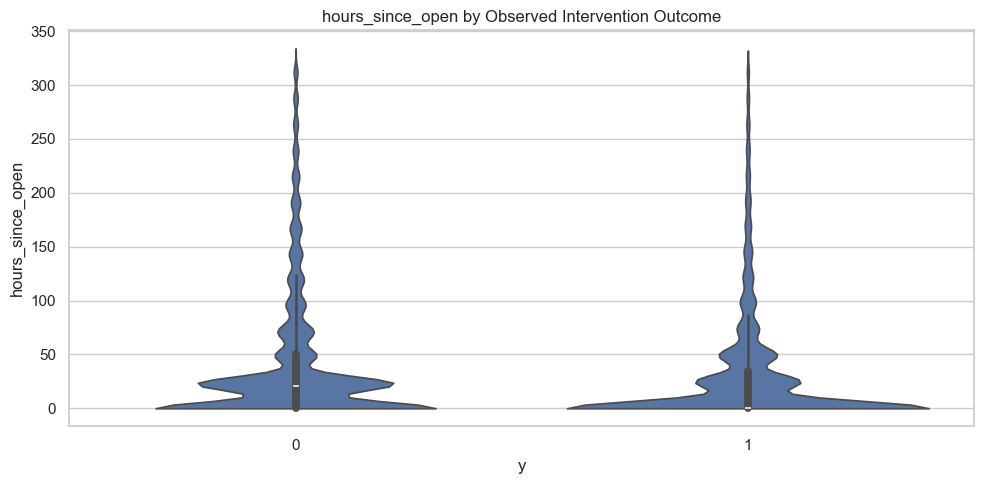


EDA INSIGHT
section: Target-Stratified Feature Behaviour
finding: hours_since_open differs between observed outcome groups.
evidence: Median y=1: 0; median y=0: 21.
statistical_support: Mann-Whitney U=1875959994.00, p=0.0000e+00, rank-biserial effect size≈0.140.
interpretation: The feature distributions show an observed difference between successful and unsuccessful intervention records.
ml_implication: hours_since_open remains a candidate signal for C3, subject to decision-time availability, stability and leakage review.
caveat: Exploratory association; not a causal treatment estimate.


In [24]:

preferred_numeric = [
    "amount_inr",
    "prior_failure_count",
    "tenure_months",
    "attempt_index",
    "time_since_first_failure_days",
    "proxy_days_to_salary",
    "hours_since_open",
]

for col in preferred_numeric:

    if col not in df_ml.columns:
        continue

    temp = df_ml[
        [col, target_col]
    ].dropna()

    if temp[col].nunique() < 5:
        continue

    plt.figure(figsize=(10, 5))
    sns.violinplot(
        data=temp,
        x=target_col,
        y=col,
        cut=0,
    )
    plt.title(
        f"{col} by Observed Intervention Outcome"
    )
    save_plot(
        f"target_stratified_{col}_violin.png"
    )

    pos = temp.loc[
        temp[target_col] == 1, col
    ]
    neg = temp.loc[
        temp[target_col] == 0, col
    ]

    if len(pos) >= 30 and len(neg) >= 30:
        u, p = stats.mannwhitneyu(
            pos,
            neg,
            alternative="two-sided"
        )

        # Effect-size approximation: rank-biserial correlation.
        n1, n0 = len(pos), len(neg)
        rank_biserial = (
            1 - (2 * u) / (n1 * n0)
        )

        record_insight(
            section="Target-Stratified Feature Behaviour",
            finding=f"{col} differs between observed outcome groups.",
            evidence=(
                f"Median y=1: {pos.median():.4g}; "
                f"median y=0: {neg.median():.4g}."
            ),
            statistical_support=(
                f"Mann-Whitney U={u:.2f}, p={p:.4e}, "
                f"rank-biserial effect size≈{rank_biserial:.3f}."
            ),
            interpretation=(
                "The feature distributions show an observed difference "
                "between successful and unsuccessful intervention records."
            ),
            ml_implication=(
                f"{col} remains a candidate signal for C3, subject to "
                "decision-time availability, stability and leakage review."
            ),
        )


## 8. Feature × Feature Relationships and Collinearity

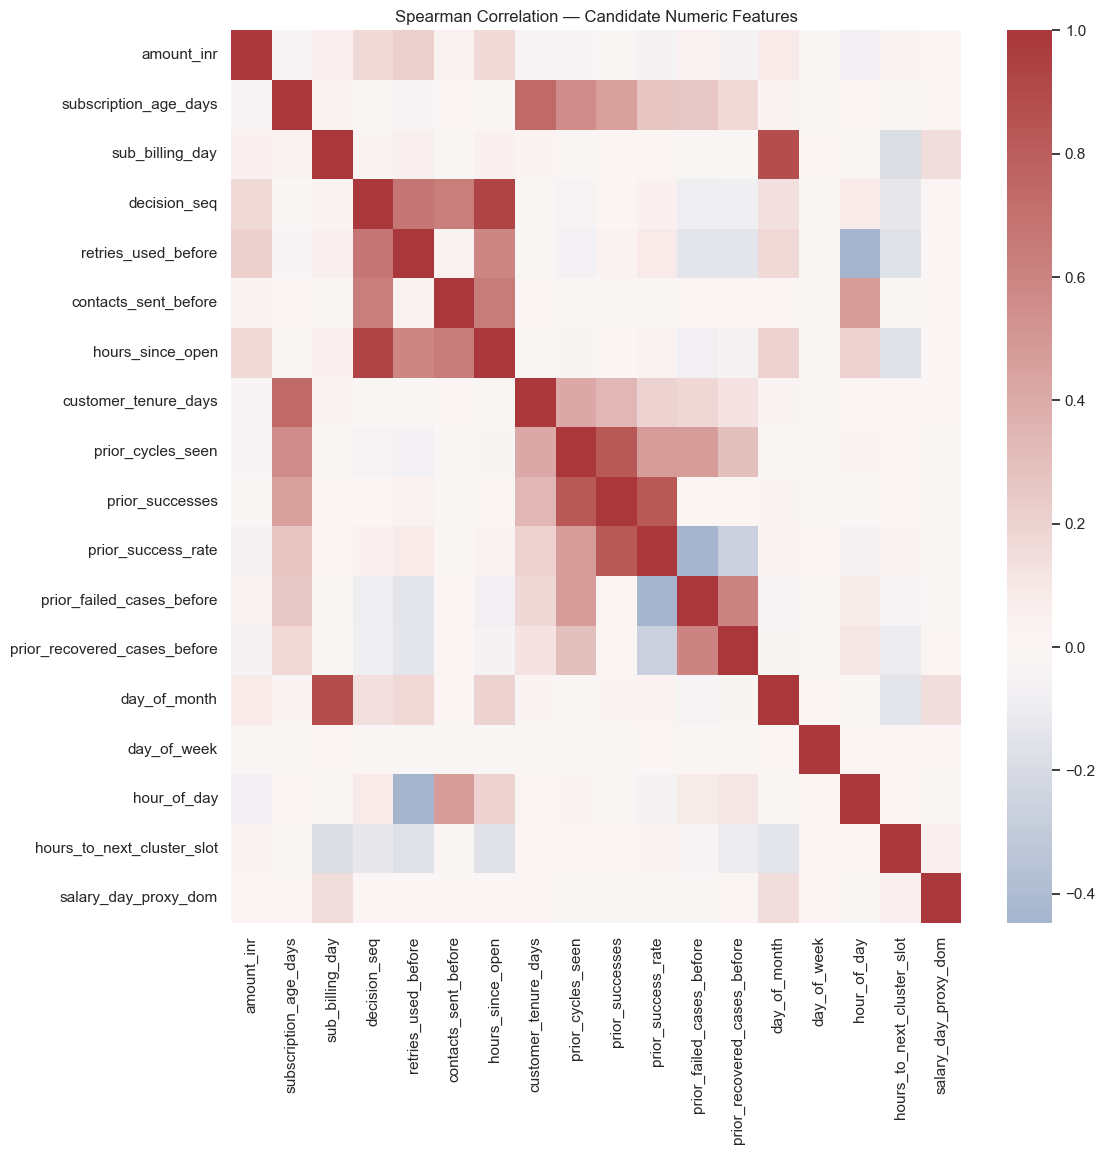

,feature_1,feature_2,spearman_abs,abs_correlation
50,decision_seq,hours_since_open,0.928010,0.928010
43,sub_billing_day,day_of_month,0.882051,0.882051
117,prior_successes,prior_success_rate,0.832934,0.832934
108,prior_cycles_seen,prior_successes,0.828139,0.828139



EDA INSIGHT
section: Feature Collinearity
finding: Highly correlated candidate feature pairs were detected.
evidence: 4 candidate pair(s) have |Spearman| >= 0.80.
statistical_support: Spearman rank correlation.
interpretation: Some candidate variables may contain overlapping information.
ml_implication: Review redundancy during C3; do not automatically drop a feature based on correlation alone.
caveat: Exploratory association; not a causal treatment estimate.


In [25]:

numeric_for_corr = [
    c for c in candidate_cols
    if c in df_ml.columns
    and pd.api.types.is_numeric_dtype(df_ml[c])
    and not pd.api.types.is_bool_dtype(df_ml[c])
    and c != target_col
]

if len(numeric_for_corr) >= 2:

    corr = df_ml[numeric_for_corr].corr(
        method="spearman"
    )

    plt.figure(
        figsize=(
            max(9, len(corr.columns) * 0.65),
            max(7, len(corr.columns) * 0.65),
        )
    )
    sns.heatmap(
        corr,
        cmap="vlag",
        center=0,
        annot=len(corr.columns) <= 12,
        fmt=".2f",
    )
    plt.title(
        "Spearman Correlation — Candidate Numeric Features"
    )
    save_plot(
        "candidate_spearman_heatmap.png"
    )

    pairs = (
        corr.where(
            np.triu(
                np.ones(corr.shape),
                k=1
            ).astype(bool)
        )
        .stack()
        .reset_index()
    )
    pairs.columns = [
        "feature_1",
        "feature_2",
        "spearman_abs",
    ]

    pairs["abs_correlation"] = pairs["spearman_abs"].abs()

    high_corr = pairs[
        pairs["abs_correlation"] >= 0.80
    ].sort_values(
        "abs_correlation",
        ascending=False,
    )

    display(high_corr)

    high_corr.to_csv(
        REPORT_DIR / "high_correlation_pairs.csv",
        index=False,
    )

    if not high_corr.empty:
        record_insight(
            section="Feature Collinearity",
            finding="Highly correlated candidate feature pairs were detected.",
            evidence=(
                f"{len(high_corr)} candidate pair(s) have "
                "|Spearman| >= 0.80."
            ),
            statistical_support="Spearman rank correlation.",
            interpretation=(
                "Some candidate variables may contain overlapping information."
            ),
            ml_implication=(
                "Review redundancy during C3; do not automatically drop a feature "
                "based on correlation alone."
            ),
        )


## 9. Graphical Anomaly / Tail Review

In [26]:

anomaly_rows = []

for col in numeric_for_corr:

    s = pd.to_numeric(
        df_ml[col],
        errors="coerce"
    ).dropna()

    if len(s) < 50 or s.nunique() < 8:
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 3 * iqr
    upper = q3 + 3 * iqr

    below = int((s < lower).sum())
    above = int((s > upper).sum())

    anomaly_rows.append({
        "feature": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_review_bound": lower,
        "upper_review_bound": upper,
        "below_count": below,
        "above_count": above,
        "outlier_pct": 100 * (below + above) / len(s),
    })

anomaly_df = pd.DataFrame(anomaly_rows)
display(anomaly_df.sort_values("outlier_pct", ascending=False))

anomaly_df.to_csv(
    REPORT_DIR / "anomaly_review.csv",
    index=False,
)

if not anomaly_df.empty:
    flagged = anomaly_df[
        anomaly_df["outlier_pct"] >= 1
    ]

    if not flagged.empty:
        record_insight(
            section="Anomaly / Tail Behaviour",
            finding="Potential heavy-tail observations were identified for review.",
            evidence=(
                f"{len(flagged)} candidate feature(s) have >=1% of observations "
                "outside the exploratory Q1-3×IQR / Q3+3×IQR review bounds."
            ),
            statistical_support="Exploratory IQR tail rule.",
            interpretation=(
                "Some distributions may contain legitimate extreme values or "
                "structural tails."
            ),
            ml_implication=(
                "Review distributions in C3 before choosing transformations; "
                "no observations are removed automatically."
            ),
        )


,feature,q1,q3,iqr,lower_review_bound,upper_review_bound,below_count,above_count,outlier_pct
12,hour_of_day,6.0,7.0,1.0,3.0,10.0,21772,9906,20.122854
0,amount_inr,299.0,999.0,700.0,-1801.0,3099.0,0,10855,6.895435
4,hours_since_open,0.0,48.0,48.0,-144.0,192.0,0,6465,4.106770
9,prior_failed_cases_before,0.0,2.0,2.0,-6.0,8.0,0,1941,1.232984
10,prior_recovered_cases_before,0.0,1.0,1.0,-3.0,4.0,0,1740,1.105302
3,decision_seq,0.0,2.0,2.0,-6.0,8.0,0,1031,0.654923
2,sub_billing_day,7.0,23.0,16.0,-41.0,71.0,0,0,0.000000
6,prior_cycles_seen,4.0,10.0,6.0,-14.0,28.0,0,0,0.000000
5,customer_tenure_days,365.0,740.0,375.0,-760.0,1865.0,0,0,0.000000
1,subscription_age_days,232.0,486.0,254.0,-530.0,1248.0,0,0,0.000000



EDA INSIGHT
section: Anomaly / Tail Behaviour
finding: Potential heavy-tail observations were identified for review.
evidence: 5 candidate feature(s) have >=1% of observations outside the exploratory Q1-3×IQR / Q3+3×IQR review bounds.
statistical_support: Exploratory IQR tail rule.
interpretation: Some distributions may contain legitimate extreme values or structural tails.
ml_implication: Review distributions in C3 before choosing transformations; no observations are removed automatically.
caveat: Exploratory association; not a causal treatment estimate.


## 10. Action Support / Selection Structure

In [27]:

support_rows = []

if "action_type" in df_ml.columns:

    overall = (
        df_ml["action_type"]
        .value_counts(dropna=False)
        .rename("support_count")
        .reset_index()
    )
    overall.columns = ["action_type", "support_count"]
    overall["dimension"] = "overall"
    overall["group"] = "all"
    support_rows.append(overall)

    for dim in [
        "failure_class_at_decision",
        "rail",
        "value_tier",
        "logging_policy",
    ]:
        if dim not in df_ml.columns:
            continue

        tmp = (
            df_ml.groupby(
                [dim, "action_type"],
                dropna=False
            )
            .size()
            .reset_index(name="support_count")
            .rename(columns={dim: "group"})
        )
        tmp["dimension"] = dim
        support_rows.append(
            tmp[
                [
                    "dimension",
                    "group",
                    "action_type",
                    "support_count",
                ]
            ]
        )

if support_rows:
    support_df = pd.concat(
        support_rows,
        ignore_index=True,
    )
    support_df["low_support_lt_100"] = (
        support_df["support_count"] < 100
    )

    display(
        support_df.sort_values("support_count").head(100)
    )

    support_df.to_csv(
        REPORT_DIR / "action_support.csv",
        index=False,
    )

    low_support = support_df[
        support_df["low_support_lt_100"]
    ]

    if not low_support.empty:
        record_insight(
            section="Action Support",
            finding="Some action/state combinations have limited support.",
            evidence=(
                f"{len(low_support)} grouped action-support cell(s) "
                "contain fewer than 100 observations."
            ),
            statistical_support="Observed support counts.",
            interpretation=(
                "Certain candidate intervention comparisons may be statistically "
                "weak because the logged dataset contains fewer examples."
            ),
            ml_implication=(
                "C3/C4/C7 must preserve support constraints and avoid overclaiming "
                "counterfactual performance in sparse action-state regions."
            ),
        )


,action_type,support_count,dimension,group,low_support_lt_100
12,SEND_REMINDER,44,failure_class_at_decision,CARD_LOST_STOLEN,True
9,SEND_REMINDER,87,failure_class_at_decision,CARD_EXPIRED,True
32,REQUEST_PM_UPDATE,108,value_tier,HIGH,False
23,SEND_REMINDER,110,failure_class_at_decision,RATE_LIMIT,False
22,SEND_PAYMENT_LINK,115,failure_class_at_decision,RATE_LIMIT,False
10,REQUEST_PM_UPDATE,142,failure_class_at_decision,CARD_LOST_STOLEN,False
11,SEND_PAYMENT_LINK,214,failure_class_at_decision,CARD_LOST_STOLEN,False
46,REQUEST_PM_UPDATE,259,logging_policy,B2_DOCTRINE,False
7,REQUEST_PM_UPDATE,288,failure_class_at_decision,CARD_EXPIRED,False
24,REQUEST_PM_UPDATE,430,rail,CARD_SI,False



EDA INSIGHT
section: Action Support
finding: Some action/state combinations have limited support.
evidence: 2 grouped action-support cell(s) contain fewer than 100 observations.
statistical_support: Observed support counts.
interpretation: Certain candidate intervention comparisons may be statistically weak because the logged dataset contains fewer examples.
ml_implication: C3/C4/C7 must preserve support constraints and avoid overclaiming counterfactual performance in sparse action-state regions.
caveat: Exploratory association; not a causal treatment estimate.


## 11. Selected Multivariate Visuals

In [28]:

pair_cols = [
    c for c in [
        "amount_inr",
        "prior_failure_count",
        "tenure_months",
        "attempt_index",
    ]
    if c in df_ml.columns
    and pd.api.types.is_numeric_dtype(df_ml[c])
]

if len(pair_cols) >= 2:

    pair_df = df_ml[
        pair_cols + [target_col]
    ].dropna()

    if len(pair_df) > 5000:
        pair_df = pair_df.sample(
            5000,
            random_state=42,
        )

    g = sns.pairplot(
        pair_df,
        vars=pair_cols,
        hue=target_col,
        corner=True,
        diag_kind="kde",
        plot_kws={"alpha": 0.35},
    )

    g.fig.suptitle(
        "Selected Candidate Feature Pairwise Structure",
        y=1.02,
    )

    g.fig.savefig(
        REPORT_DIR / "selected_candidate_pairplot.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close("all")


## 12. Advanced Insight Report

In [29]:

df_insights = pd.DataFrame(insights_log)

if df_insights.empty:
    df_insights = pd.DataFrame(
        columns=[
            "section",
            "finding",
            "evidence",
            "statistical_support",
            "interpretation",
            "ml_implication",
            "caveat",
        ]
    )

df_insights.to_csv(
    REPORT_DIR / "advanced_insights.csv",
    index=False,
)

summary = {
    "target_column": target_col,
    "ml_rows": int(len(df_ml)),
    "unique_cases": (
        int(df_ml["case_id"].nunique())
        if "case_id" in df_ml.columns
        else None
    ),
    "unique_customers": (
        int(df_ml["customer_id"].nunique())
        if "customer_id" in df_ml.columns
        else None
    ),
    "candidate_features": int(len(candidate_cols)),
    "insights_generated": int(len(df_insights)),
}

with open(
    REPORT_DIR / "c2b_summary.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(summary, f, indent=2)

lines = [
    "# Phase C2B — Advanced Graphical EDA Findings",
    "",
    "This report contains findings calculated from normalized Dataset V1.",
    "Observed intervention outcomes are associations, not causal effects.",
    "",
]

for _, row in df_insights.iterrows():
    lines.extend([
        f"## {row['section']}",
        f"- **Finding:** {row['finding']}",
        f"- **Evidence:** {row['evidence']}",
        f"- **Statistical support:** {row['statistical_support']}",
        f"- **Interpretation:** {row['interpretation']}",
        f"- **ML implication:** {row['ml_implication']}",
        f"- **Caveat:** {row['caveat']}",
        "",
    ])

(DOCS_DIR / "C2B_GRAPHICAL_EDA_FINDINGS.md").write_text(
    "\n".join(lines),
    encoding="utf-8",
)

print("C2B completed.")
print("Plots/reports:", REPORT_DIR)
print("Findings:", DOCS_DIR / "C2B_GRAPHICAL_EDA_FINDINGS.md")


C2B completed.
Plots/reports: c:\Users\Soham\Documents\revenue-recovery\reports\eda_graphical
Findings: c:\Users\Soham\Documents\revenue-recovery\docs\C2B_GRAPHICAL_EDA_FINDINGS.md
